<a href="https://colab.research.google.com/github/leviribeiro7/experimento-gan-tcc/blob/main/Experimento_GAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 📥 Configuração Inicial do Ambiente

Este bloco de código prepara o ambiente do Google Colab para executar o projeto, realizando duas etapas fundamentais:

1. **Clonagem do Repositório:** Baixa o código-fonte e a estrutura do projeto do GitHub (`Master-s-degree`) diretamente para a máquina virtual do Colab.
2. **Instalação de Dependências:** Instala as bibliotecas necessárias para manipulação, processamento e visualização de imagens:
   - `opencv-python`: Usada para leitura, redimensionamento, aplicação de filtros e salvamento das imagens (`cv2`).
   - `matplotlib`: Utilizada posteriormente para plotar e exibir os resultados gráficos no notebook.

In [1]:
!git clone https://github.com/CristianoLimaOliveira/Master-s-degree.git
!pip install opencv-python matplotlib

Cloning into 'Master-s-degree'...
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 52 (delta 1), reused 20 (delta 1), pack-reused 30 (from 1)
Receiving objects: 100% (52/52), 56.83 MiB | 26.20 MiB/s, done.
Resolving deltas: 100% (6/6), done.


### 🌐 Download e Extração do Dataset (Seguro)

Este bloco faz o download automatizado do dataset [faces-dataset-small](https://www.kaggle.com/datasets/tommykamaz/faces-dataset-small) do Kaggle de forma segura, utilizando os recursos integrados do Google Colab:

1. **Leitura Segura do Token:** O código busca o token de acesso armazenado previamente nos **Secrets** do Colab (`userdata.get`), evitando que a sua chave de API fique exposta publicamente no código-fonte.
2. **Download do Dataset:** Utiliza a CLI do Kaggle para baixar o dataset `tommykamaz/faces-dataset-small`.
3. **Descompactação:** Extrai o conteúdo compactado diretamente para a pasta `/content/dataset_original` de forma otimizada e limpa.

In [2]:
import os
from google.colab import userdata

# Pega o token de forma segura direto dos Secrets do Colab
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

!kaggle datasets download -d tommykamaz/faces-dataset-small
!unzip -q faces-dataset-small.zip -d /content/dataset_original
print("Dataset baixado e descompactado com sucesso!")

Dataset URL: https://www.kaggle.com/datasets/tommykamaz/faces-dataset-small
License(s): Attribution 4.0 International (CC BY 4.0)
100% 3.99G/3.99G [00:38<00:00, 113MB/s] 

Dataset baixado e descompactado com sucesso!


### 📁 Organização e Pré-processamento do Dataset (Super-Resolution)

Este bloco de código prepara a estrutura de pastas e as imagens para o treinamento de um modelo de **Super-Resolução (Upscale 2x)**.

#### 🔍 O que este código faz:
1. **Criação da Estrutura de Diretórios:** Cria as pastas de `training` (treino), `validation` (validação) e `testing` (teste), contendo os subdiretórios `hr` (High Resolution) e `lr` (Low Resolution).
2. **Seleção das Imagens:** Busca até 500 imagens (`.jpg`, `.jpeg`, `.png`) a partir do diretório de origem (`/content/dataset_original`).
3. **Função de Processamento (`processar_imagens`):**
   - **HR (Alta Resolução):** Redimensiona a imagem original para exatamente **128x128 pixels** utilizando interpolação cúbica.
   - **LR (Baixa Resolução):** Aplica um filtro *Gaussian Blur* na imagem HR e depois a redimensiona para **64x64 pixels** (criando a degradação para simular o aumento de escala em 2x).
4. **Divisão dos Dados:** Distribui as 500 imagens nas proporções definidas:
   - **400 imagens** para Treinamento (`training`)
   - **50 imagens** para Validação (`validation`)
   - **50 imagens** para Teste (`testing`)

In [3]:
import cv2
import os
from pathlib import Path

base_dir = '/content/Master-s-degree/dataset'
splits = ['training', 'validation', 'testing']

for split in splits:
    os.makedirs(f'{base_dir}/{split}/hr', exist_ok=True)
    os.makedirs(f'{base_dir}/{split}/lr', exist_ok=True)

pasta_origem = Path('/content/dataset_original')
caminho_imagens = list(pasta_origem.rglob('*.jpg')) + list(pasta_origem.rglob('*.jpeg')) + list(pasta_origem.rglob('*.png'))
caminho_imagens = [str(p) for p in caminho_imagens][:500]

def processar_imagens(lista_imagens, pasta_fase):
    contador = 0
    for img_path in lista_imagens:
        img = cv2.imread(img_path)
        if img is None: continue

        # Mantém HR em 128x128
        img_hr = cv2.resize(img, (128, 128), interpolation=cv2.INTER_CUBIC)
        nome_arquivo = f"img_{contador:04d}.png"
        cv2.imwrite(f'{base_dir}/{pasta_fase}/hr/{nome_arquivo}', img_hr)

        # Altera a degradação LR para 64x64 (para casar com o upscale 2x do modelo)
        img_blur = cv2.GaussianBlur(img_hr, (5, 5), 0)
        img_lr = cv2.resize(img_blur, (64, 64), interpolation=cv2.INTER_LINEAR)
        cv2.imwrite(f'{base_dir}/{pasta_fase}/lr/{nome_arquivo}', img_lr)

        contador += 1
    print(f"-> {contador} imagens prontas para tensores em {pasta_fase}.")

print("Corrigindo as dimensões...")
processar_imagens(caminho_imagens[:400], 'training')
processar_imagens(caminho_imagens[400:450], 'validation')
processar_imagens(caminho_imagens[450:], 'testing')

Corrigindo as dimensões...
-> 400 imagens prontas para tensores em training.
-> 50 imagens prontas para tensores em validation.
-> 50 imagens prontas para tensores em testing.


### ⚙️ Ajuste Automático das Configurações (`config.py`)

Este bloco de código modifica dinamicamente o arquivo de configuração do projeto (`config.py`) para adaptar os hiperparâmetros e recursos do modelo ao ambiente atual do Google Colab:

1. **Ajuste de Resolução:** Altera a resolução de alta qualidade (`HIGH_RES`) de 160 para **128**, casando exatamente com as dimensões dos tensores que preparamos no pré-processamento.
2. **Otimização de Hardware:**
   - Reduz o `NUM_WORKERS` para **2** (evitando gargalos ou travamentos na GPU do Colab).
   - Diminui o `BATCH_SIZE` para **4** e o `NUM_EPOCHS` para **10** (para garantir um teste rápido e seguro que caiba na memória da GPU).
3. **Controle de Treinamento:** Define `LOAD_MODEL = False` para iniciar um treinamento do zero.

In [4]:
# Célula de Correção Automática do config.py
caminho = '/content/Master-s-degree/src/realesrgan/config.py'

with open(caminho, 'r') as f:
    texto = f.read()

# Ajustando a resolução para casar com os nossos tensores (128)
texto = texto.replace('HIGH_RES = 160', 'HIGH_RES = 128')

# Garantindo as configurações do nosso teste (para não travar a GPU)
texto = texto.replace('NUM_WORKERS = 16', 'NUM_WORKERS = 2')
texto = texto.replace('LOAD_MODEL = True', 'LOAD_MODEL = False')
texto = texto.replace('NUM_EPOCHS = 160', 'NUM_EPOCHS = 10')
texto = texto.replace('BATCH_SIZE = 16', 'BATCH_SIZE = 4')

with open(caminho, 'w') as f:
    f.write(texto)

print("config.py corrigido com sucesso! Resolucao base alterada para 128.")

config.py corrigido com sucesso! Resolucao base alterada para 128.


In [ ]:
# Código para atualizar o script principal de execução do treino direto pelo Colab

caminho_main = '/content/Master-s-degree/src/realesrgan/main.py' # Ajuste o nome do arquivo se for 'train.py'

# Lendo o conteúdo atual
with open(caminho_main, 'r') as f:
    conteudo = f.read()

# Substituindo a chamada antiga da train_fn para incluir o parâmetro 'epoch'
antigo = """gen, disc, history_loss = train_fn(
        loader,
        disc,
        gen,
        opt_gen,
        opt_disc,
        mse,
        pix,
        bce,
        vgg_loss,
        history_loss
    )"""

novo = """gen, disc, history_loss = train_fn(
        loader,
        disc,
        gen,
        opt_gen,
        opt_disc,
        mse,
        pix,
        bce,
        vgg_loss,
        history_loss,
        epoch
    )"""

if antigo in conteudo:
    conteudo_atualizado = conteudo.replace(antigo, novo)
    with open(caminho_main, 'w') as f:
        f.write(conteudo_atualizado)
    print("✅ Chamada do 'train_fn' atualizada com sucesso no script principal!")
else:
    print("⚠️ Não foi possível localizar o trecho exato no arquivo. Verifique se o nome das variáveis ou do arquivo é diferente.")

### 🚀 Inicialização do Treinamento (Real-ESRGAN)

Este é o bloco principal onde o modelo de super-resolução começa a ser treinado:

1. **Mudança de Diretório (`%cd`):** Navega para a pasta do código-fonte do Real-ESRGAN (`/content/Master-s-degree/src/realesrgan`), que é o local de onde o script de treinamento precisa ser executado.
2. **Execução do Treinamento:** Roda o script `train_realesrgan.py` definindo a variável de ambiente `PYTHONPATH` para garantir que o Python encontre corretamente todos os módulos do projeto. A partir daqui, o modelo começará a aprender a mapear as imagens de baixa resolução (`lr`) para alta resolução (`hr`).

In [5]:
%cd /content/Master-s-degree/src/realesrgan
!PYTHONPATH="/content/Master-s-degree/src" python train_realesrgan.py

/content/Master-s-degree/src/realesrgan
I0000 00:00:1793252523.111775    3319 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793252527.042754    3319 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth
100% 548M

### 📊 Visualização da Evolução dos Experimentos

Este código automatiza a busca e exibição dos resultados de um modelo ao longo das épocas de treinamento para uma amostra específica.

**O que este script faz:**
1. **Busca Automática:** Varre recursivamente o diretório de experimentos localizando imagens (`.png` e `.jpg`) que contêm o identificador da amostra (`nome_amostra`).
2. **Ordenação Temporal:** Organiza os arquivos encontrados em ordem cronológica.
3. **Painel 1 (Evolução Completa):** Exibe todas as etapas geradas lado a lado para acompanhar o progresso gradual do modelo.
4. **Painel 2 (Comparação Antes/Depois):** Destaca lado a lado a **primeira** e a **última** época gerada, facilitando a avaliação rápida dos ganhos de qualidade.

✅ Encontradas 9 imagens para análise.

=== 1. EVOLUÇÃO COMPLETA AO LONGO DAS ÉPOCAS ===


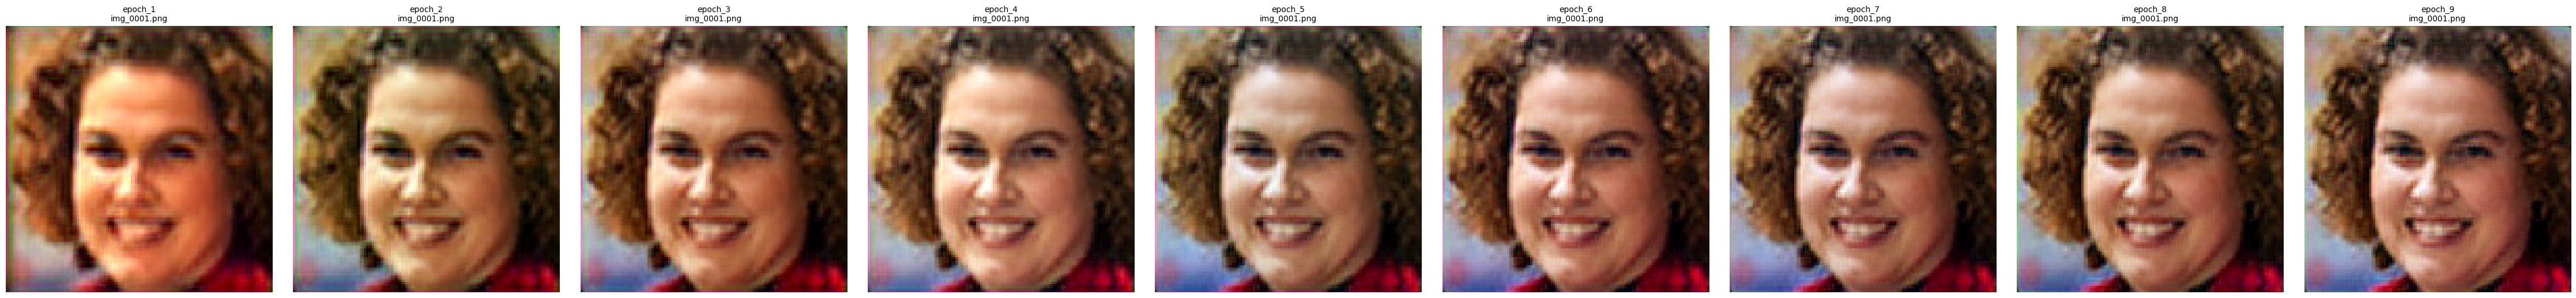


=== 2. COMPARAÇÃO DIRETA: PRIMEIRA VS. ÚLTIMA ÉPOCA ===


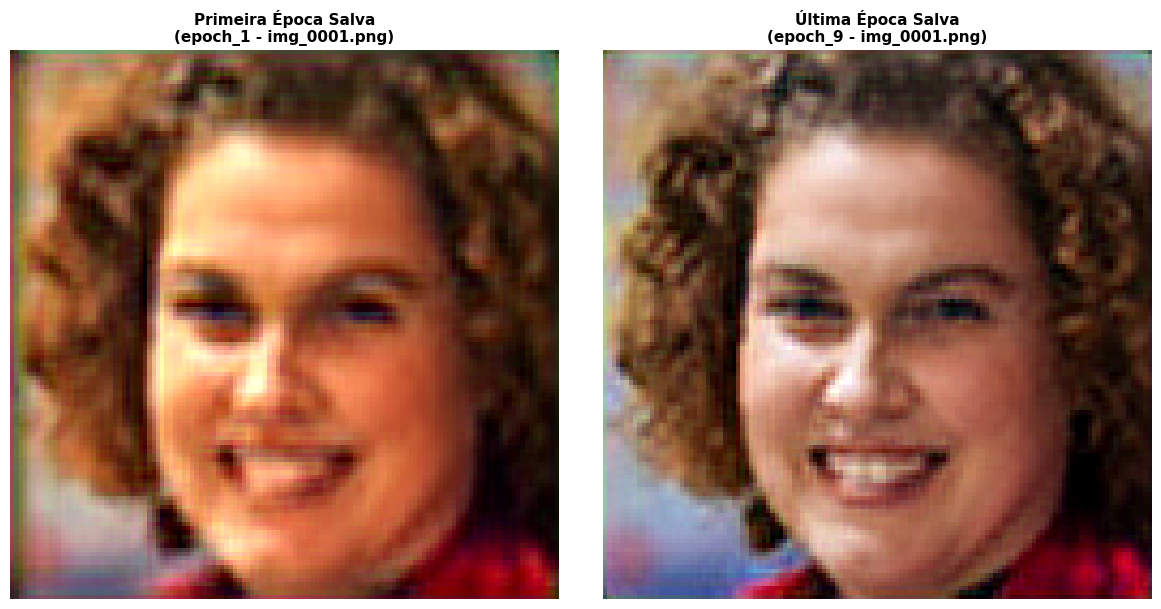

In [26]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import glob
import os

pasta_experimentos = '/content/Master-s-degree/experiments'

# Substitua 'img_0001' pelo padrão do nome da sua imagem de teste
nome_amostra = 'img_0001'

# Busca todas as ocorrências dessa amostra específica nas subpastas
imagens = glob.glob(os.path.join(pasta_experimentos, '**', f'*{nome_amostra}*.png'), recursive=True) + \
          glob.glob(os.path.join(pasta_experimentos, '**', f'*{nome_amostra}*.jpg'), recursive=True)

if imagens:
    # Ordena as imagens em ordem cronológica
    imagens_ordenadas = sorted(imagens)
    qtd_imagens = len(imagens_ordenadas)
    print(f"✅ Encontradas {qtd_imagens} imagens para análise.\n")

    # =========================================================
    # 1. LINHA DO TEMPO COMPLETA (TODAS AS ÉPOCAS LADO A LADO)
    # =========================================================
    print("=== 1. EVOLUÇÃO COMPLETA AO LONGO DAS ÉPOCAS ===")
    fig, axes = plt.subplots(1, qtd_imagens, figsize=(5 * qtd_imagens, 5))

    if qtd_imagens == 1:
        axes = [axes]

    for idx, caminho_img in enumerate(imagens_ordenadas):
        img = mpimg.imread(caminho_img)
        nome_pasta = os.path.basename(os.path.dirname(caminho_img))

        axes[idx].imshow(img)
        axes[idx].set_title(f"{nome_pasta}\n{os.path.basename(caminho_img)}", fontsize=10)
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

    # =========================================================
    # 2. COMPARAÇÃO DIRETA: PRIMEIRA VS. ÚLTIMA ÉPOCA
    # =========================================================
    if qtd_imagens > 1:
        print("\n=== 2. COMPARAÇÃO DIRETA: PRIMEIRA VS. ÚLTIMA ÉPOCA ===")

        primeira_e_ultima = [imagens_ordenadas[0], imagens_ordenadas[-1]]
        titulos = ["Primeira Época Salva", "Última Época Salva"]

        fig, axes = plt.subplots(1, 2, figsize=(12, 6))

        for idx, caminho_img in enumerate(primeira_e_ultima):
            img = mpimg.imread(caminho_img)
            nome_pasta = os.path.basename(os.path.dirname(caminho_img))

            axes[idx].imshow(img)
            axes[idx].set_title(f"{titulos[idx]}\n({nome_pasta} - {os.path.basename(caminho_img)})", fontsize=11, fontweight='bold')
            axes[idx].axis('off')

        plt.tight_layout()
        plt.show()
    else:
        print("\n⚠️ Apenas 1 época foi encontrada até o momento, portanto a comparação direta foi ignorada.")

else:
    print(f"❌ Nenhuma imagem correspondente a '*{nome_amostra}*' foi encontrada nas subpastas.")

### 📉 Monitoramento das Funções de Perda (Losses) do Gerador e Discriminador

Este código carrega o histórico de treinamento do modelo a partir do arquivo de *checkpoint* e gera gráficos para analisar o comportamento das perdas ao longo do tempo.

**O que este script faz:**
1. **Carregamento de Dados:** Lê o arquivo `.pth` salvo (`gen.pth`) e extrai o histórico de *loss* (`history_loss`).
2. **Separação das Métricas:** Extrai as perdas individuais do Gerador (Pixel, Perceptual e Adversarial/GAN) e do Discriminador (Real e Fake).
3. **Suavização (*Smoothing*):** Aplica uma média móvel de janela simples nas curvas do Discriminador para reduzir o ruído visual e facilitar a leitura da tendência.
4. **Gráfico do Gerador:** Exibe a evolução das perdas $L_{pix}$, $L_{percep}$ e $L_{gan}$ em um subpainel.
5. **Gráfico do Discriminador:** Exibe o comportamento do Discriminador ao classificar amostras reais e geradas/falsas no subpainel inferior.

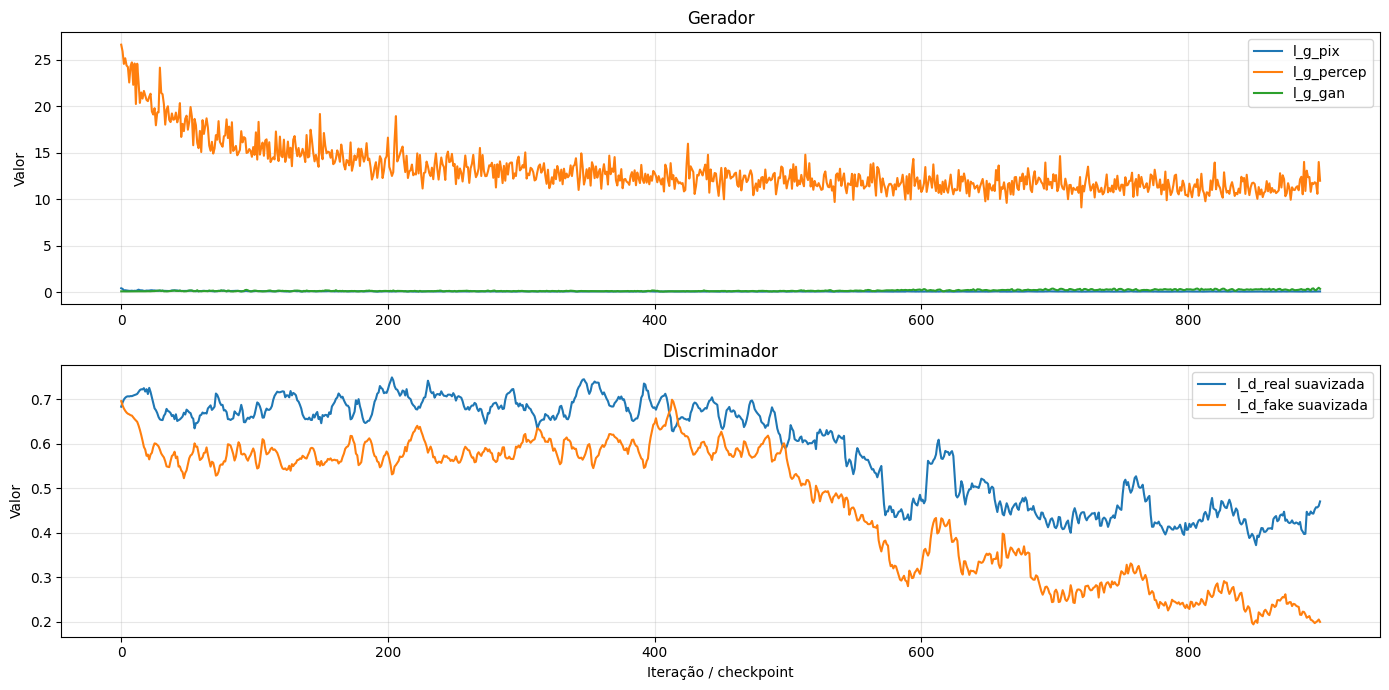

In [27]:
import torch
import matplotlib.pyplot as plt

ckpt = torch.load("/content/Master-s-degree/checkpoints/gen.pth", map_location="cpu")
history = ckpt["history_loss"]

pix = []
percep = []
gan = []
d_real = []
d_fake = []

for entry in history:
    pix.append(float(entry["l_g_pix"]))
    percep.append(float(entry["l_g_percep"]))
    gan.append(float(entry["l_g_gan"]))
    d_real.append(float(entry["l_d_real"]))
    d_fake.append(float(entry["l_d_fake"]))

def smooth(values, window=10):
    if len(values) < 2:
        return values
    smoothed = []
    for i in range(len(values)):
        start = max(0, i - window)
        end = min(len(values), i + window + 1)
        smoothed.append(sum(values[start:end]) / (end - start))
    return smoothed

plt.figure(figsize=(14, 7))

plt.subplot(2, 1, 1)
plt.plot(pix, label="l_g_pix")
plt.plot(percep, label="l_g_percep")
plt.plot(gan, label="l_g_gan")
plt.title("Gerador")
plt.ylabel("Valor")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(smooth(d_real), label="l_d_real suavizada")
plt.plot(smooth(d_fake), label="l_d_fake suavizada")
plt.title("Discriminador")
plt.xlabel("Iteração / checkpoint")
plt.ylabel("Valor")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 📏 Avaliação Quantitativa de Qualidade de Imagem (PSNR & SSIM)

Este código compara a imagem gerada pelo modelo (*Super-Resolution*) com a imagem original de alta resolução (*High Resolution / Gabarito*) utilizando métricas matemáticas consolidadas.

**O que este script faz:**
1. **Carregamento & Validação:** Lê os arquivos de imagem com OpenCV (`cv2`) e verifica a existência de ambos antes do cálculo para evitar erros de execução.
2. **Redimensionamento de Segurança:** Alinha as dimensões da imagem gerada com as do gabarito original, garantindo compatibilidade matemática pixel a pixel.
3. **Cálculo do PSNR (*Peak Signal-to-Noise Ratio*):** Mede a quantidade de ruído/erro na imagem reconstruída. Quanto **maior** o valor em dB, mais próxima e "limpa" está a imagem.
4. **Cálculo do SSIM (*Structural Similarity Index*):** Avalia a fidelidade estrutural, de textura e de brilho em relação ao original. Retorna um valor entre **0 e 1** (sendo **1** a correspondência perfeita).

In [20]:
import cv2
import os
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

# Substitua pelo caminho EXATO da imagem que o script 1 encontrou
caminho_imagem_gerada = '/content/Master-s-degree/experiments/epoch_9/img_0019.png'

# Caminho do gabarito original (HR) correspondente da pasta de teste
caminho_gabarito = '/content/Master-s-degree/dataset/testing/hr/img_0019.png'

try:
    # Carrega as imagens
    img_sr = cv2.imread(caminho_imagem_gerada)
    img_hr = cv2.imread(caminho_gabarito)

    # === VALIDAÇÃO DE SEGURANÇA ===
    # Se o OpenCV não encontrar o arquivo, a variável fica "None".
    # Interrompemos o código aqui antes que o 'resize' quebre.
    if img_sr is None:
        raise FileNotFoundError(f"A imagem gerada não foi encontrada no caminho: {caminho_imagem_gerada}")
    if img_hr is None:
        raise FileNotFoundError(f"O gabarito não foi encontrado no caminho: {caminho_gabarito}")

    # Garante que estão no mesmo tamanho para a matemática não quebrar
    img_sr = cv2.resize(img_sr, (img_hr.shape[1], img_hr.shape[0]))

    # Calcula as métricas
    valor_psnr = psnr(img_hr, img_sr)
    valor_ssim = ssim(img_hr, img_sr, channel_axis=2) # channel_axis=2 lida com imagens RGB

    print("=== MÉTRICAS PARA O RELATÓRIO ===")
    print(f"PSNR: {valor_psnr:.2f} dB (Quanto maior, mais limpa a imagem)")
    print(f"SSIM: {valor_ssim:.4f} (De 0 a 1. Quanto mais perto de 1, mais fiel)")

except Exception as e:
    print(f"\n[ERRO] Não foi possível calcular as métricas.\nDetalhe: {e}")

=== MÉTRICAS PARA O RELATÓRIO ===
PSNR: 8.12 dB (Quanto maior, mais limpa a imagem)
SSIM: 0.0959 (De 0 a 1. Quanto mais perto de 1, mais fiel)
